# Pain Axis: Local Jupyter Starter Replication

This notebook reproduces a **small pilot** of Sections 3.2–3.3 of [Tagliabue, Dung & Berg (2026)](https://arxiv.org/abs/2609.16247), using **Gemma 2 2B** and the original **S2_1P** dataset. It extracts the final-token residual representation at **one fixed decoder layer (layer 13, zero-indexed)**, builds a denoised pain vector from training sentences, and evaluates ROC-AUC on held-out sentences.

**Important:** This is *not* an exact paper-wide replication. The authors select the extraction layer using cross-validation across all layers; this quick-start uses a fixed layer so the first run is simpler.

Run **all cells from top to bottom** using *Kernel → Restart Kernel and Run All Cells*. Do not jump directly to the `X_test @ pain_vector` cell.

**Setup in your `pain-axis` conda environment** (terminal):
```bash
pip install torch transformers accelerate sentencepiece huggingface_hub numpy pandas scikit-learn matplotlib jupyterlab ipykernel
```

Gemma may require accepting Google's Hugging Face model terms and logging in using `huggingface-cli login` / `hf auth login`. GPU recommended; CPU is much slower. This notebook never clears your Hugging Face cache or changes other downloaded models.

## 1. Imports and hardware check

In [1]:
import json
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))
else:
    print("CPU mode: activation extraction may be slow, and you need enough system RAM.")

PyTorch: 2.2.1+cu121
Device: cuda
GPU: NVIDIA GeForce GTX 1080 Ti
GPU memory (GB): 11.7


## 2. Load the authors’ original S2 first-person dataset

Uses a local copy if available; otherwise downloads **only the JSON dataset**, not the entire repository.

In [2]:
relative_path = Path("datasets/3.1_pain_and_control_datasets.json")
candidates = [
    relative_path,
    Path("Pain-axis") / relative_path,
    Path("..") / "Pain-axis" / relative_path,
]
source = next((p for p in candidates if p.is_file()), None)
if source is None:
    source = Path("3.1_pain_and_control_datasets.json")
    if not source.is_file():
        url = ("https://raw.githubusercontent.com/valen-research/"
               "Pain-axis/main/datasets/3.1_pain_and_control_datasets.json")
        urlretrieve(url, source)

with open(source, encoding="utf-8") as f:
    raw = json.load(f)
rows = raw["datasets"]["S2_1P"]["sentences"]
df = pd.DataFrame(rows)
pain_categories = {"A1", "A2", "A3", "A4", "A5"}
df["y"] = df["category"].isin(pain_categories).astype(int)

print("Loaded", len(df), "sentences from", source)
print(df.groupby(["category", "y"]).size())
assert len(df) == 200, "Unexpected dataset length: inspect the source JSON."
assert df.y.sum() == 100, "Expected 100 pain examples."
df.head()

Loaded 200 sentences from Pain-axis/datasets/3.1_pain_and_control_datasets.json
category  y
A1        1    20
A2        1    20
A3        1    20
A4        1    20
A5        1    20
B         0    20
C1        0    20
C2        0    20
D         0    20
E         0    20
dtype: int64


,category,set,prompt,y
0,A1,1,The knife slices into my finger. I feel:,1
1,A1,2,My tooth throbs with each heartbeat. I feel:,1
2,A1,3,A migraine pounds behind my eyes. I feel:,1
3,A1,4,I twist my ankle on the stairs. I feel:,1
4,A1,5,The hot oil splatters onto my arm. I feel:,1


## 3. Load the model

If you get a 401/403 error, accept the Gemma model license at Hugging Face and authenticate from your terminal. You may need to restart the notebook. Initial model download is several GB.

In [3]:
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "google/gemma-2-2b"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=DTYPE,
    low_cpu_mem_usage=True,
)
model = model.to(DEVICE)
model.eval()

print("Number of decoder layers:", model.config.num_hidden_layers)
print("Hidden dimension:", model.config.hidden_size)

tokenizer.model:   0%|          | 0.00/4.24M [00:00<?, ?B/s]

2026-10-28 20:03:21.382179: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-28 20:03:21.382247: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-28 20:03:21.383727: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-28 20:03:21.393313: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


model.safetensors.index.json: 0.00B [00:00, ?B/s]

model-00001-of-00003.safetensors:   0%|          | 0.00/4.99G [00:00<?, ?B/s]

model-00002-of-00003.safetensors:   0%|          | 0.00/4.98G [00:00<?, ?B/s]

model-00003-of-00003.safetensors:   0%|          | 0.00/481M [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/168 [00:00<?, ?B/s]

Number of decoder layers: 26
Hidden dimension: 2304


## 4. Extract final-token activations at one fixed layer

Hugging Face's `hidden_states` tuple starts with the embedding output. We therefore use `hidden_states[LAYER + 1]` as the output of zero-indexed decoder block `LAYER`. For a deeper exact replication, confirm architecture-specific layer and normalization conventions against the authors’ extraction script.

The activations are cached locally so you do not have to rerun the model after restarting your kernel.

In [4]:
LAYER = 13  # zero-indexed decoder block; pilot choice, not the paper's CV-selected layer
assert 0 <= LAYER < model.config.num_hidden_layers

cache_file = Path(f"gemma2_2b_S2_1P_layer{LAYER}_activations.npz")

if cache_file.is_file():
    saved = np.load(cache_file)
    X = saved["X"]
    print("Loaded saved activations from", cache_file)
else:
    vectors = []
    with torch.inference_mode():
        for i, prompt in enumerate(df["prompt"]):
            inputs = tokenizer(prompt, return_tensors="pt").to(DEVICE)
            result = model(**inputs, output_hidden_states=True, use_cache=False)
            hidden = result.hidden_states[LAYER + 1][0, -1, :]
            vectors.append(hidden.float().cpu().numpy())
            if (i + 1) % 25 == 0:
                print(f"Extracted {i+1}/{len(df)} prompts")
    X = np.asarray(vectors, dtype=np.float32)
    np.savez_compressed(cache_file, X=X)
    print("Saved activations to", cache_file)

y = df["y"].to_numpy()
categories = df["category"].to_numpy()
assert X.shape == (len(df), model.config.hidden_size)
print("X:", X.shape, "y:", y.shape)

Extracted 25/200 prompts
Extracted 50/200 prompts
Extracted 75/200 prompts
Extracted 100/200 prompts
Extracted 125/200 prompts
Extracted 150/200 prompts
Extracted 175/200 prompts
Extracted 200/200 prompts
Saved activations to gemma2_2b_S2_1P_layer13_activations.npz
X: (200, 2304) y: (200,)


## 5. Split the data: this defines `X_test` and `y_test`

In [5]:
train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.20,
    random_state=42,
    stratify=categories,  # preserve all 10 category proportions
)
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("Test labels:", np.bincount(y_test))

X_train: (160, 2304) X_test: (40, 2304)
Test labels: [20 20]


## 6. Extract a denoised pain vector using **training data only**

Mean(pain) − mean(controls), then project away principal components explaining 50% of the variance among **training controls**. The test data are never used to fit the direction.

In [6]:
pain_train = X_train[y_train == 1]
control_train = X_train[y_train == 0]

raw_direction = pain_train.mean(axis=0) - control_train.mean(axis=0)
pca = PCA(n_components=0.50, svd_solver="full")
pca.fit(control_train)
U = pca.components_
pain_vector = raw_direction - U.T @ (U @ raw_direction)
norm = np.linalg.norm(pain_vector)
assert norm > 1e-12, "Denoised vector has zero length."
pain_vector = pain_vector / norm

print("Removed", pca.n_components_, "control principal components")
print("pain_vector:", pain_vector.shape)

Removed 6 control principal components
pain_vector: (2304,)


## 7. Compute held-out ROC-AUC: all three variables now exist

In [7]:
scores = X_test @ pain_vector
auc = roc_auc_score(y_test, scores)
print(f"Held-out ROC-AUC: {auc:.3f}")

Held-out ROC-AUC: 0.925


## 8. Plot ROC curve and examine scores

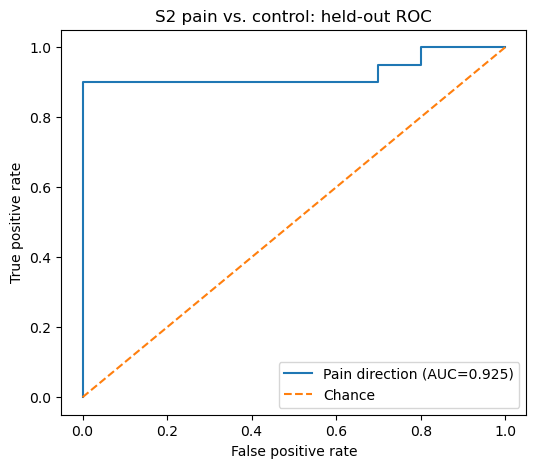

,category,prompt,y,projection
73,A4,My greed caused my family to lose everything. ...,1,27.319843
76,A4,I participated in something I knew was wrong. ...,1,25.964581
74,A4,I manipulated someone who loved me. I feel:,1,25.117992
93,A5,My assumptions about the world were naive. I f...,1,22.162380
62,A4,I chose my career over my dying father. I feel:,1,21.524837
83,A5,The complexity of the decision overwhelms me. ...,1,20.789967
46,A3,My family disowns me for my choices. I feel:,1,20.580963
94,A5,I struggle to process the implications. I feel:,1,19.321754
37,A2,I cannot access my own feelings anymore. I feel:,1,19.315950
95,A5,The framework I trusted completely fails me. I...,1,19.088634


In [8]:
fpr, tpr, thresholds = roc_curve(y_test, scores)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f"Pain direction (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", label="Chance")
ax.set(xlabel="False positive rate", ylabel="True positive rate",
       title="S2 pain vs. control: held-out ROC")
ax.legend()
plt.show()

score_table = df.iloc[test_idx][["category", "prompt", "y"]].copy()
score_table["projection"] = scores
display(score_table.sort_values("projection", ascending=False).head(10))

## Interpretation and next steps

- `X` contains measured model activations, not text embeddings invented for the demonstration.
- `X_train` is used to fit the pain direction. `X_test` is held out to calculate AUC.
- This **fixed-layer 80/20 split** is a fast sanity check; it **cannot be compared directly** with the authors’ 5-fold cross-validated layer-selection experiment. For a closer replication, collect activations across all decoder layers, select layers using proper nested/held-out folds, and use the authors’ validation scripts for S1/S2 and additional controls.
- An AUC noticeably below the paper’s range does not necessarily mean your code is incorrect: layer choice, model revision, activation definition, and split can all affect the result.

Original repository: https://github.com/valen-research/Pain-axis